# **Analisis Pola Pembelian Konsumen Menggunakan Algoritma Apriori dan FP-Growth pada Dataset Retail Market Basket**


Kelompok 8 :  

1. Adisti Eka Nabila (24031554119)
2. Umi Imro'atus Sholekhah (24031554150)
3. Maris Al Sabina Azzuhra (24031554188)

link dataset : https://www.kaggle.com/datasets/wasiqaliyasir/retail-market-basket-transactions-dataset

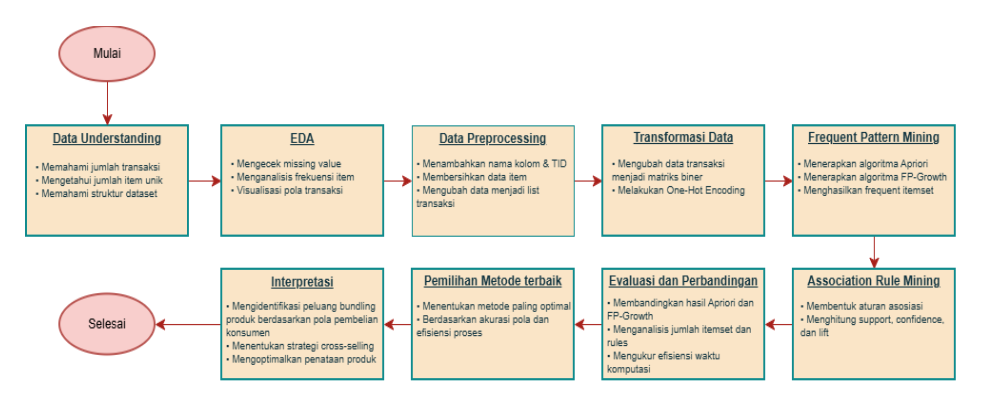

# **1. IMPORT LIBRARY**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
from google.colab import drive

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import fpgrowth
from mlxtend.frequent_patterns import association_rules

import warnings
warnings.filterwarnings('ignore')

import time

# **2. LOAD DATASET**

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv(
    '/content/drive/Shareddrives/project_Data Mining/Market_Basket_Optimisation.csv',header=None)

df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# **3. DATA UNDERSTANDING**

## 3.1 Dimensi Dataset

In [ ]:
df.shape


(7501, 20)

## 3.2 Tipe Data

In [ ]:
df.dtypes

,0
0,object
1,object
2,object
3,object
4,object
5,object
6,object
7,object
8,object
9,object


# **4. EXPLORATORY DATA ANALYSIS (EDA)**

## 4.1 Mengecek Missing Value

In [ ]:
missing_values = df.isnull().sum()

missing_values

missing_values.sum()

np.int64(120657)

## 4.2 Menambahkan Nama Kolom

In [ ]:
column_names = []

for i in range(1, 21):

    column_names.append(f'Item{i}')

df.columns = column_names

df.columns

Index(['Item1', 'Item2', 'Item3', 'Item4', 'Item5', 'Item6', 'Item7', 'Item8',
       'Item9', 'Item10', 'Item11', 'Item12', 'Item13', 'Item14', 'Item15',
       'Item16', 'Item17', 'Item18', 'Item19', 'Item20'],
      dtype='object')

## 4.3 Menghitung Jumlah Item Unik

In [ ]:
all_items = []

for col in df.columns:

    items = df[col].dropna().tolist()

    all_items.extend(items)

clean_items = []

for item in all_items:

    item = str(item).lower().strip()

    clean_items.append(item)

unique_items = set(clean_items)

len(unique_items)


119

## 4.4 Menghitung Frekuensi Kemunculan Item

In [ ]:
item_counter = Counter(clean_items)

top_items = item_counter.most_common(10)

top_items_df = pd.DataFrame(
    top_items,
    columns=['Item', 'Frekuensi']
)

top_items_df

,Item,Frekuensi
0,mineral water,1788
1,eggs,1348
2,spaghetti,1306
3,french fries,1282
4,chocolate,1230
5,green tea,991
6,milk,972
7,ground beef,737
8,frozen vegetables,715
9,pancakes,713


## 4.5 Visualisasi Top Item

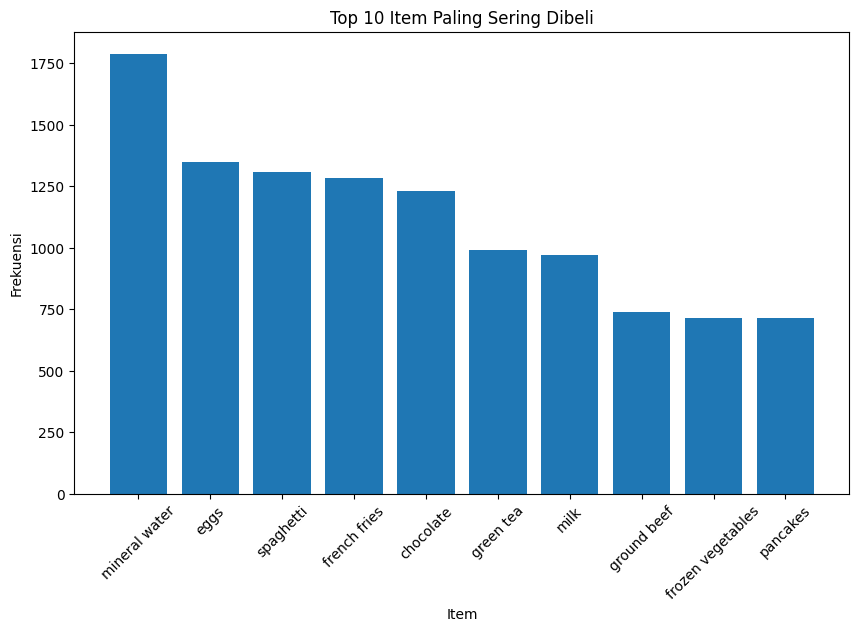

In [ ]:
plt.figure(figsize=(10,6))

plt.bar(
    top_items_df['Item'],
    top_items_df['Frekuensi']
)

plt.xticks(rotation=45)

plt.title("Top 10 Item Paling Sering Dibeli")

plt.xlabel("Item")

plt.ylabel("Frekuensi")

plt.show()

## 4.6 Distribusi Jumlah Item per Transaksi

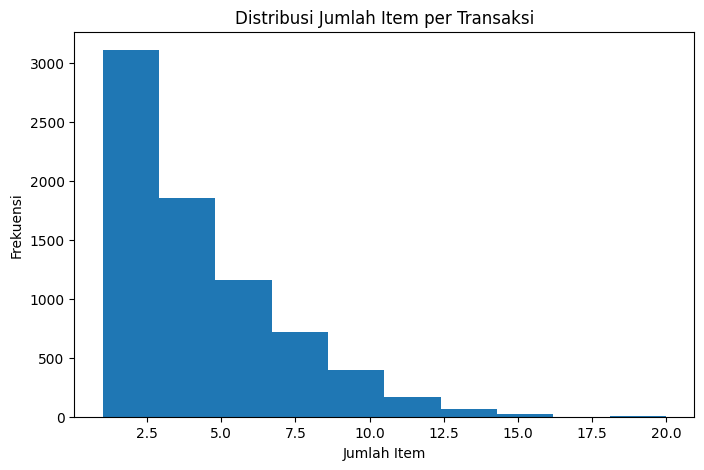

In [ ]:
item_per_transaction = df.notnull().sum(axis=1)

item_per_transaction.describe()

plt.figure(figsize=(8,5))

plt.hist(item_per_transaction, bins=10)

plt.title("Distribusi Jumlah Item per Transaksi")

plt.xlabel("Jumlah Item")

plt.ylabel("Frekuensi")

plt.show()

## 4.7 Deteksi Outlier Jumlah Item per Transaksi

In [ ]:
Q1 = item_per_transaction.quantile(0.25)

Q3 = item_per_transaction.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR
outliers = item_per_transaction[
    (item_per_transaction < lower_bound) |
    (item_per_transaction > upper_bound)
]

len(outliers)

395

In [ ]:
outliers.head()

,0
0,20
18,10
56,11
91,12
107,10


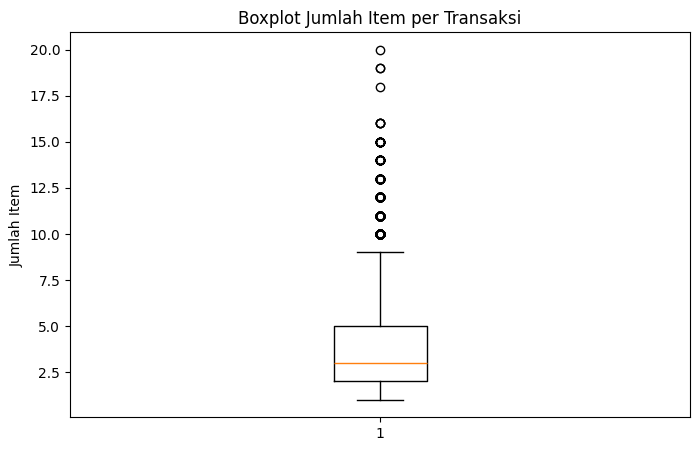

In [ ]:
plt.figure(figsize=(8,5))

plt.boxplot(item_per_transaction)

plt.title('Boxplot Jumlah Item per Transaksi')

plt.ylabel('Jumlah Item')

plt.show()

# **5. DATA PREPROCESSING**


## 5.1 Menambahkan Transaction ID (TID)

In [ ]:
df.insert(0, 'TID', range(1, len(df)+1))

df.head()

,TID,Item1,Item2,Item3,Item4,Item5,Item6,Item7,Item8,Item9,...,Item11,Item12,Item13,Item14,Item15,Item16,Item17,Item18,Item19,Item20
0,1,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,...,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,2,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5.2 Pembersihan Nama Item

In [ ]:
for col in column_names:

    df[col] = df[col].astype(str)

    df[col] = df[col].str.lower()

    df[col] = df[col].str.strip()

df.replace('nan', np.nan, inplace=True)

df.head()

,TID,Item1,Item2,Item3,Item4,Item5,Item6,Item7,Item8,Item9,...,Item11,Item12,Item13,Item14,Item15,Item16,Item17,Item18,Item19,Item20
0,1,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,...,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,2,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5.3 Pemeriksaan Duplikasi

In [ ]:
duplicate_count = df[column_names].duplicated().sum()
duplicate_count

np.int64(2325)

In [ ]:
duplicate_check = df[['TID'] + column_names].copy()

duplicate_check['transaction_key'] = duplicate_check[column_names].apply(
    lambda row: tuple(sorted(row.dropna().tolist())),
    axis=1
)

duplicate_check['Item_Dalam_Transaksi'] = duplicate_check['transaction_key'].apply(
    lambda x: ', '.join(x)
)

duplicate_groups = (
    duplicate_check
    .groupby('transaction_key')
    .agg({
        'TID': list,
        'Item_Dalam_Transaksi': 'first'
    })
    .reset_index()
)

duplicate_groups['Jumlah_TID_Sama'] = duplicate_groups['TID'].apply(len)

duplicate_groups = duplicate_groups[duplicate_groups['Jumlah_TID_Sama'] > 1]

duplicate_groups['TID_Acuan'] = duplicate_groups['TID'].apply(lambda x: x[0])
duplicate_groups['TID_Yang_Sama'] = duplicate_groups['TID'].apply(lambda x: x[1:])

duplicate_tid_summary = duplicate_groups[
    ['TID_Acuan', 'TID_Yang_Sama', 'Jumlah_TID_Sama', 'Item_Dalam_Transaksi']
].reset_index(drop=True)

duplicate_tid_summary.head(20)

,TID_Acuan,TID_Yang_Sama,Jumlah_TID_Sama,Item_Dalam_Transaksi
0,254,[7454],2,almonds
1,2850,"[3193, 3706, 3707, 5528, 5759, 6646]",7,antioxydant juice
2,628,[3312],2,"antioxydant juice, chocolate"
3,349,[4274],2,"antioxydant juice, escalope"
4,276,[2902],2,"antioxydant juice, spaghetti"
5,5608,[5822],2,asparagus
6,929,"[1918, 2469, 3063, 4203, 4714, 4895]",7,avocado
7,624,"[1357, 5924, 6829, 7397]",5,"avocado, mineral water"
8,4,[3175],2,"avocado, turkey"
9,3376,[4610],2,"avocado, yogurt cake"


## 5.4 Transformasi Menjadi List Transaksi

In [ ]:
transactions = []

for i in range(len(df)):

    transaction = []

    for col in column_names:

        item = df.loc[i, col]

        if pd.notnull(item):

            transaction.append(item)

    transactions.append(transaction)

transactions[:5]

[['shrimp',
  'almonds',
  'avocado',
  'vegetables mix',
  'green grapes',
  'whole weat flour',
  'yams',
  'cottage cheese',
  'energy drink',
  'tomato juice',
  'low fat yogurt',
  'green tea',
  'honey',
  'salad',
  'mineral water',
  'salmon',
  'antioxydant juice',
  'frozen smoothie',
  'spinach',
  'olive oil'],
 ['burgers', 'meatballs', 'eggs'],
 ['chutney'],
 ['turkey', 'avocado'],
 ['mineral water', 'milk', 'energy bar', 'whole wheat rice', 'green tea']]

# **6. Transformasi Data**

## 6.1 One Hot Encoding

In [ ]:
te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)

transaction_matrix = pd.DataFrame(
    te_array,
    columns=te.columns_,
    index=df['TID']
).astype(int)

transaction_matrix.head()


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
TID,,,,,,,,,,,,,,,,,,,,,
1,1,1,0,1,0,0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


## 6.2 Ukuran Matriks

In [ ]:
transaction_matrix.shape

(7501, 119)

# **7. TUNNING Minimum Support**

In [ ]:
support_values = [0.005, 0.01, 0.015, 0.02, 0.03, 0.05]

min_confidence_default = 0.3

hasil_tuning_support = []

for supp in support_values:

    # APRIORI

    start_apriori = time.time()

    frequent_apriori_test = apriori(
        transaction_matrix,
        min_support=supp,
        use_colnames=True
    )

    end_apriori = time.time()

    apriori_runtime = end_apriori - start_apriori

    rules_apriori_test = association_rules(
        frequent_apriori_test,
        metric='confidence',
        min_threshold=min_confidence_default
    )

    rules_apriori_test = rules_apriori_test[
        rules_apriori_test['lift'] > 1
    ]

    # FP-GROWTH

    start_fp = time.time()

    frequent_fp_test = fpgrowth(
        transaction_matrix,
        min_support=supp,
        use_colnames=True
    )

    end_fp = time.time()

    fp_runtime = end_fp - start_fp

    rules_fp_test = association_rules(
        frequent_fp_test,
        metric='confidence',
        min_threshold=min_confidence_default
    )

    rules_fp_test = rules_fp_test[
        rules_fp_test['lift'] > 1
    ]

    # SIMPAN HASIL

    hasil_tuning_support.append({

        'Minimum Support': supp,

        'Minimal Transaksi':
        round(supp * len(transaction_matrix)),

        # APRIORI
        'Apriori Frequent Itemset':
        len(frequent_apriori_test),

        'Apriori Rules':
        len(rules_apriori_test),

        'Apriori Avg Lift':
        rules_apriori_test['lift'].mean(),

        'Apriori Runtime':
        apriori_runtime,

        # FP-GROWTH
        'FP Frequent Itemset':
        len(frequent_fp_test),

        'FP Rules':
        len(rules_fp_test),

        'FP Avg Lift':
        rules_fp_test['lift'].mean(),

        'FP Runtime':
        fp_runtime
    })

hasil_tuning_support_df = pd.DataFrame(
    hasil_tuning_support
)

hasil_tuning_support_df

,Minimum Support,Minimal Transaksi,Apriori Frequent Itemset,Apriori Rules,Apriori Avg Lift,Apriori Runtime,FP Frequent Itemset,FP Rules,FP Avg Lift,FP Runtime
0,0.005,38,725,261,1.992709,2.707264,725,261,1.992709,17.688323
1,0.010,75,257,63,1.774213,0.454493,257,63,1.774213,5.467793
2,0.015,113,153,37,1.722553,0.322308,153,37,1.722553,3.543888
3,0.020,150,103,20,1.618080,0.161078,103,20,1.618080,1.322475
4,0.030,225,54,7,1.634422,0.063761,54,7,1.634422,0.498903
5,0.050,375,28,2,1.393709,0.032821,28,2,1.393709,0.159975


## Visualisasi Jumlah Rules

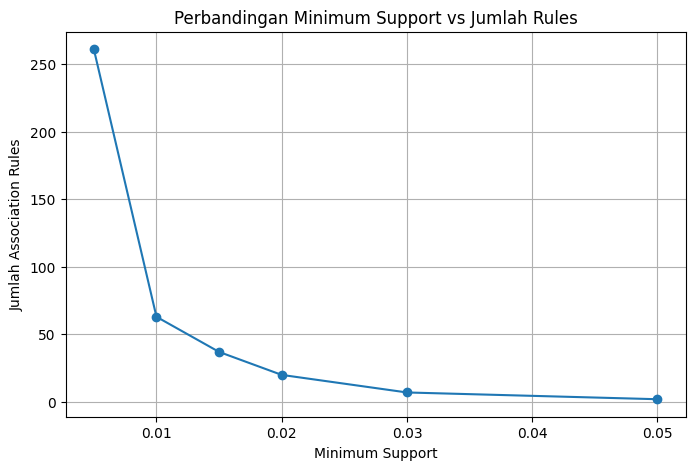

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    hasil_tuning_support_df['Minimum Support'],
    hasil_tuning_support_df['FP Rules'],
    marker='o'
)

plt.xlabel('Minimum Support')

plt.ylabel('Jumlah Association Rules')

plt.title('Perbandingan Minimum Support vs Jumlah Rules')

plt.grid()

plt.show()

## Visualisasi AVG Lift

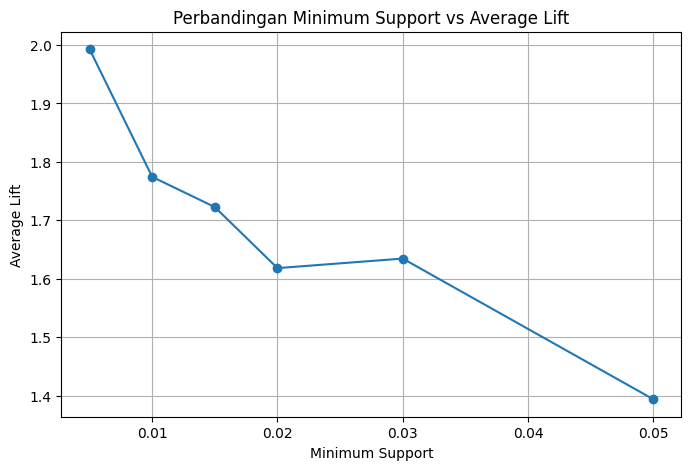

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    hasil_tuning_support_df['Minimum Support'],
    hasil_tuning_support_df['FP Avg Lift'],
    marker='o'
)

plt.xlabel('Minimum Support')

plt.ylabel('Average Lift')

plt.title('Perbandingan Minimum Support vs Average Lift')

plt.grid()

plt.show()

## Visualisasi Runtime

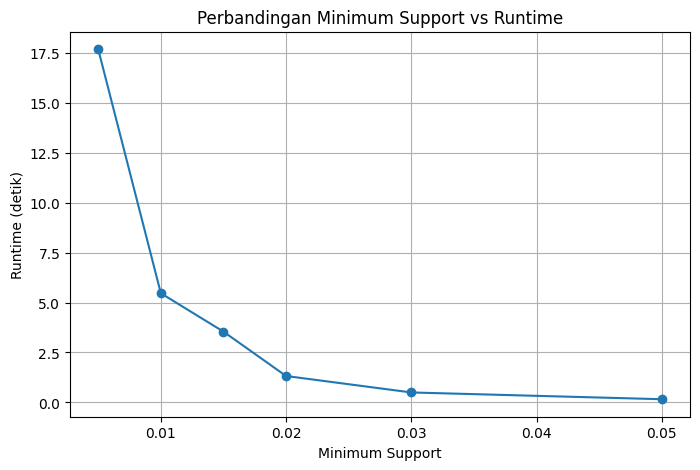

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    hasil_tuning_support_df['Minimum Support'],
    hasil_tuning_support_df['FP Runtime'],
    marker='o'
)

plt.xlabel('Minimum Support')

plt.ylabel('Runtime (detik)')

plt.title('Perbandingan Minimum Support vs Runtime')

plt.grid()

plt.show()

# **8. FREQUENT PATTERN MINING — APRIORI**

In [ ]:
start_apriori = time.time()

frequent_apriori = apriori(
    transaction_matrix,
    min_support=0.01,
    use_colnames=True
)

end_apriori = time.time()

time_apriori = end_apriori - start_apriori

## Hasil Frequent Itemset Apriori

In [ ]:
frequent_apriori = frequent_apriori.sort_values(
    by='support',
    ascending=False
)

frequent_apriori.head(10)

,support,itemsets
46,0.238368,(mineral water)
19,0.179709,(eggs)
63,0.174110,(spaghetti)
24,0.170911,(french fries)
13,0.163845,(chocolate)
32,0.132116,(green tea)
45,0.129583,(milk)
33,0.098254,(ground beef)
30,0.095321,(frozen vegetables)
53,0.095054,(pancakes)


In [ ]:
total_frequent_apriori = len(frequent_apriori)

total_frequent_apriori

257

## Visualisasi Frequent Itemset Apriori

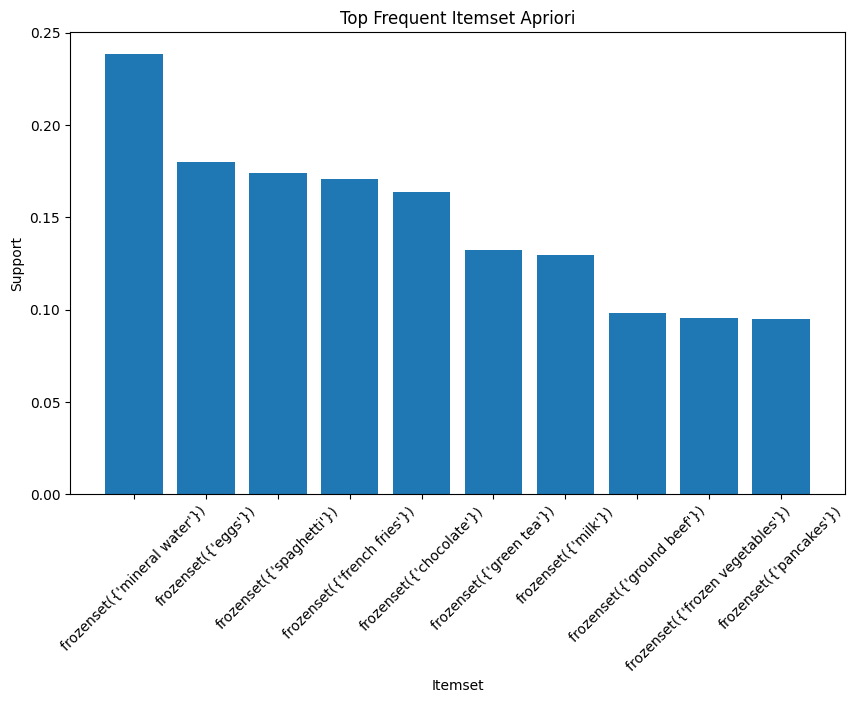

In [ ]:
top_apriori = frequent_apriori.head(10).copy()

top_apriori['itemsets'] = top_apriori['itemsets'].astype(str)

plt.figure(figsize=(10,6))

plt.bar(
    top_apriori['itemsets'],
    top_apriori['support']
)

plt.xticks(rotation=45)

plt.title('Top Frequent Itemset Apriori')

plt.xlabel('Itemset')

plt.ylabel('Support')

plt.show()

# **9. FREQUENT PATTERN MINING — FP GROWTH**

In [ ]:
start_fp = time.time()

frequent_fp = fpgrowth(
    transaction_matrix,
    min_support=0.01,
    use_colnames=True
)

end_fp = time.time()

time_fp = end_fp - start_fp

## Hasil Frequent Itemset FP-Growth

In [ ]:
frequent_fp = frequent_fp.sort_values(
    by='support',
    ascending=False
)

frequent_fp.head(10)

,support,itemsets
0,0.238368,(mineral water)
15,0.179709,(eggs)
26,0.174110,(spaghetti)
22,0.170911,(french fries)
31,0.163845,(chocolate)
1,0.132116,(green tea)
19,0.129583,(milk)
50,0.098254,(ground beef)
27,0.095321,(frozen vegetables)
43,0.095054,(pancakes)


In [ ]:
total_frequent_fp = len(frequent_fp)

total_frequent_fp

257

## Visualisasi Frequent Itemset FP-Growth

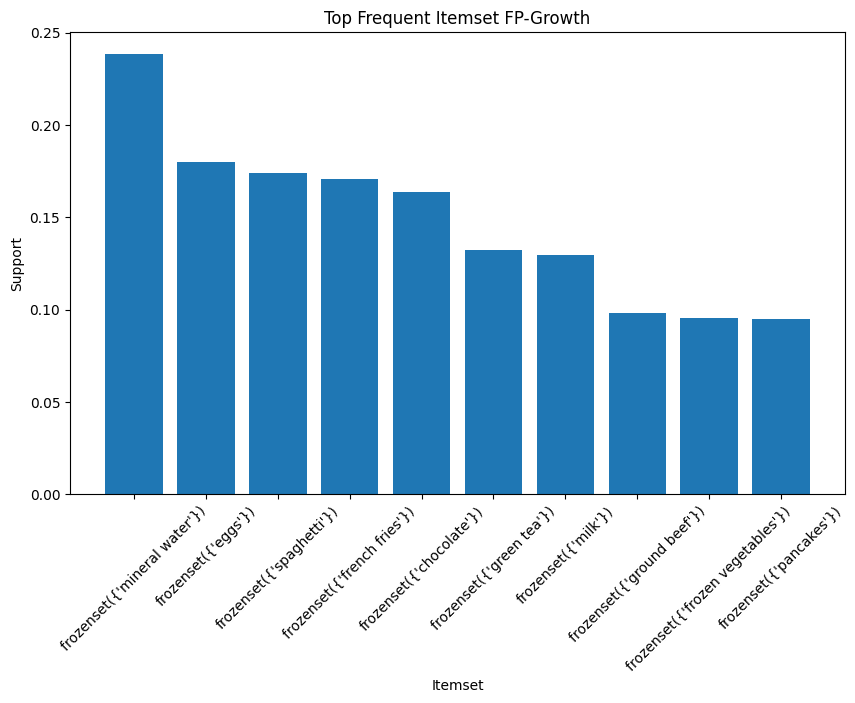

In [ ]:
top_fp = frequent_fp.head(10).copy()

top_fp['itemsets'] = top_fp['itemsets'].astype(str)

plt.figure(figsize=(10,6))

plt.bar(
    top_fp['itemsets'],
    top_fp['support']
)

plt.xticks(rotation=45)

plt.title('Top Frequent Itemset FP-Growth')

plt.xlabel('Itemset')

plt.ylabel('Support')

plt.show()

# **10. UJI MINIMUM CONFIDENCE**

In [ ]:
confidence_values = [0.2, 0.3, 0.4, 0.5]

hasil_confidence = []

for conf in confidence_values:

    # APRIORI
    rules_ap = association_rules(
        frequent_apriori,
        metric='confidence',
        min_threshold=conf
    )

    rules_ap = rules_ap[rules_ap['lift'] > 1]

    # FP-GROWTH
    rules_fp = association_rules(
        frequent_fp,
        metric='confidence',
        min_threshold=conf
    )

    rules_fp = rules_fp[rules_fp['lift'] > 1]

    hasil_confidence.append({

        'Minimum Confidence': conf,

        'Apriori Rules':
            len(rules_ap),

        'Apriori Avg Confidence':
            rules_ap['confidence'].mean(),

        'Apriori Avg Lift':
            rules_ap['lift'].mean(),

        'FP-Growth Rules':
            len(rules_fp),

        'FP-Growth Avg Confidence':
            rules_fp['confidence'].mean(),

        'FP-Growth Avg Lift':
            rules_fp['lift'].mean()
    })

hasil_confidence_df = pd.DataFrame(
    hasil_confidence
)

hasil_confidence_df

,Minimum Confidence,Apriori Rules,Apriori Avg Confidence,Apriori Avg Lift,FP-Growth Rules,FP-Growth Avg Confidence,FP-Growth Avg Lift
0,0.2,160,0.289397,1.648743,160,0.289397,1.648743
1,0.3,63,0.368276,1.774213,63,0.368276,1.774213
2,0.4,18,0.441415,1.887683,18,0.441415,1.887683
3,0.5,2,0.504848,2.117935,2,0.504848,2.117935


## Visualisasi Perbandingan Min Conf

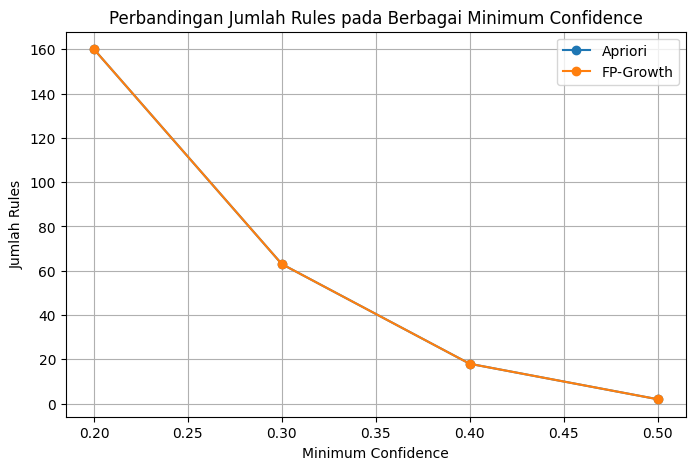

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    hasil_confidence_df['Minimum Confidence'],
    hasil_confidence_df['Apriori Rules'],
    marker='o',
    label='Apriori'
)

plt.plot(
    hasil_confidence_df['Minimum Confidence'],
    hasil_confidence_df['FP-Growth Rules'],
    marker='o',
    label='FP-Growth'
)

plt.title(
    'Perbandingan Jumlah Rules pada Berbagai Minimum Confidence'
)

plt.xlabel('Minimum Confidence')

plt.ylabel('Jumlah Rules')

plt.legend()

plt.grid()

plt.show()

# **11. ASSOCIATION RULES — APRIORI**

In [ ]:
rules_apriori = association_rules(
    frequent_apriori,
    metric='confidence',
    min_threshold=0.3
)

rules_apriori = rules_apriori[
    rules_apriori['lift'] > 1
]

rules_apriori = rules_apriori.sort_values(
    by='lift',
    ascending=False
)

rules_apriori.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
29,(herb & pepper),(ground beef),0.049460,0.098254,0.015998,0.323450,3.291994,1.0,0.011138,1.332860,0.732460,0.121457,0.249734,0.243136
23,"(mineral water, ground beef)",(spaghetti),0.040928,0.174110,0.017064,0.416938,2.394681,1.0,0.009938,1.416470,0.607262,0.086195,0.294020,0.257474
48,"(mineral water, frozen vegetables)",(milk),0.035729,0.129583,0.011065,0.309701,2.389991,1.0,0.006435,1.260929,0.603138,0.071737,0.206934,0.197546
35,(soup),(milk),0.050527,0.129583,0.015198,0.300792,2.321232,1.0,0.008651,1.244861,0.599484,0.092158,0.196697,0.209038
4,(ground beef),(spaghetti),0.098254,0.174110,0.039195,0.398915,2.291162,1.0,0.022088,1.373997,0.624943,0.168096,0.272197,0.312015
57,"(mineral water, olive oil)",(spaghetti),0.027596,0.174110,0.010265,0.371981,2.136468,1.0,0.005460,1.315071,0.547034,0.053621,0.239585,0.215470
62,"(ground beef, eggs)",(mineral water),0.019997,0.238368,0.010132,0.506667,2.125563,1.0,0.005365,1.543848,0.540342,0.040816,0.352268,0.274586
50,"(ground beef, milk)",(mineral water),0.021997,0.238368,0.011065,0.503030,2.110308,1.0,0.005822,1.532552,0.537969,0.044385,0.347493,0.274725
56,(red wine),(spaghetti),0.028130,0.174110,0.010265,0.364929,2.095966,1.0,0.005368,1.300468,0.538028,0.053472,0.231046,0.211944
14,(olive oil),(spaghetti),0.065858,0.174110,0.022930,0.348178,1.999758,1.0,0.011464,1.267048,0.535186,0.105651,0.210764,0.239939


In [ ]:
total_rules_ap = len(rules_apriori)

total_rules_ap

63

In [ ]:
rules_apriori.to_csv("rules apriori",index=False)

# **12. ASSOCIATION RULES — FP GROWTH**

In [ ]:
rules_fp = association_rules(
    frequent_fp,
    metric='confidence',
    min_threshold=0.3
)

rules_fp = rules_fp[
    rules_fp['lift'] > 1
]

rules_fp = rules_fp.sort_values(
    by='lift',
    ascending=False
)

rules_fp.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
29,(herb & pepper),(ground beef),0.049460,0.098254,0.015998,0.323450,3.291994,1.0,0.011138,1.332860,0.732460,0.121457,0.249734,0.243136
24,"(mineral water, ground beef)",(spaghetti),0.040928,0.174110,0.017064,0.416938,2.394681,1.0,0.009938,1.416470,0.607262,0.086195,0.294020,0.257474
48,"(mineral water, frozen vegetables)",(milk),0.035729,0.129583,0.011065,0.309701,2.389991,1.0,0.006435,1.260929,0.603138,0.071737,0.206934,0.197546
35,(soup),(milk),0.050527,0.129583,0.015198,0.300792,2.321232,1.0,0.008651,1.244861,0.599484,0.092158,0.196697,0.209038
4,(ground beef),(spaghetti),0.098254,0.174110,0.039195,0.398915,2.291162,1.0,0.022088,1.373997,0.624943,0.168096,0.272197,0.312015
57,"(mineral water, olive oil)",(spaghetti),0.027596,0.174110,0.010265,0.371981,2.136468,1.0,0.005460,1.315071,0.547034,0.053621,0.239585,0.215470
62,"(ground beef, eggs)",(mineral water),0.019997,0.238368,0.010132,0.506667,2.125563,1.0,0.005365,1.543848,0.540342,0.040816,0.352268,0.274586
50,"(ground beef, milk)",(mineral water),0.021997,0.238368,0.011065,0.503030,2.110308,1.0,0.005822,1.532552,0.537969,0.044385,0.347493,0.274725
59,(red wine),(spaghetti),0.028130,0.174110,0.010265,0.364929,2.095966,1.0,0.005368,1.300468,0.538028,0.053472,0.231046,0.211944
14,(olive oil),(spaghetti),0.065858,0.174110,0.022930,0.348178,1.999758,1.0,0.011464,1.267048,0.535186,0.105651,0.210764,0.239939


In [ ]:
total_rules_fp = len(rules_fp)

total_rules_fp

63

In [ ]:
rules_fp.to_csv("rules apriori",index=False)

In [ ]:
rules_apriori_check = rules_apriori[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
].sort_values(by=['support', 'confidence', 'lift']).reset_index(drop=True)

rules_fp_check = rules_fp[
    ['antecedents', 'consequents', 'support', 'confidence', 'lift']
].sort_values(by=['support', 'confidence', 'lift']).reset_index(drop=True)

rules_apriori_check.equals(rules_fp_check)

True

# **13. VISUALISASI ASSOCIATION RULES**

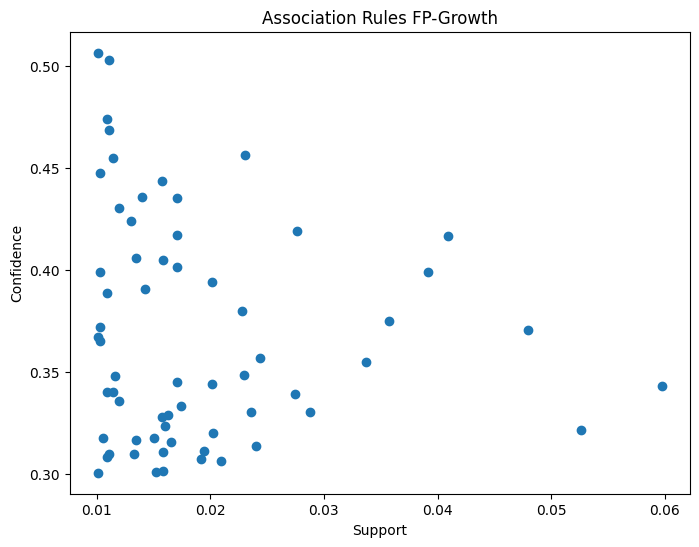

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    rules_fp['support'],
    rules_fp['confidence']
)

plt.title('Association Rules FP-Growth')

plt.xlabel('Support')

plt.ylabel('Confidence')

plt.show()

# **14. EVALUASI DAN PERBANDINGAN**

In [ ]:
comparison = pd.DataFrame({

    'Metode': ['Apriori', 'FP-Growth'],

    'Jumlah Frequent Itemset': [
        len(frequent_apriori),
        len(frequent_fp)
    ],

    'Jumlah Association Rules': [
        len(rules_apriori),
        len(rules_fp)
    ],

    'Rata-rata Confidence': [
        rules_apriori['confidence'].mean(),
        rules_fp['confidence'].mean()
    ],

    'Rata-rata Lift': [
        rules_apriori['lift'].mean(),
        rules_fp['lift'].mean()
    ],

    'Waktu Komputasi (detik)': [
        time_apriori,
        time_fp
    ]
})

comparison

,Metode,Jumlah Frequent Itemset,Jumlah Association Rules,Rata-rata Confidence,Rata-rata Lift,Waktu Komputasi (detik)
0,Apriori,257,63,0.368276,1.774213,0.438047
1,FP-Growth,257,63,0.368276,1.774213,4.670108


## Visualisasi Waktu Komputasi

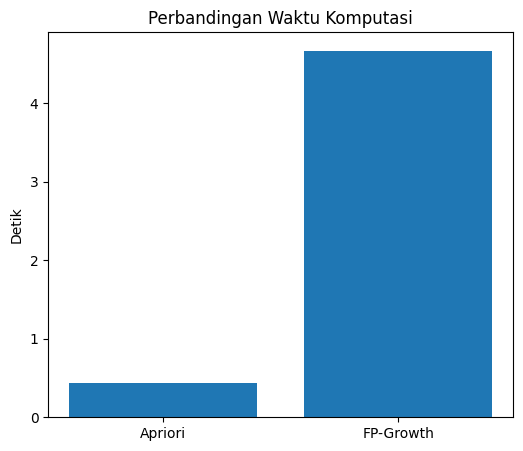

In [ ]:
plt.figure(figsize=(6,5))

plt.bar(
    comparison['Metode'],
    comparison['Waktu Komputasi (detik)']
)

plt.title('Perbandingan Waktu Komputasi')

plt.ylabel('Detik')

plt.show()

# **15. INTERPRETASI HASIL (Rules Terbaik)**

In [ ]:
rules_apriori[['antecedents',
          'consequents',
          'support',
          'confidence',
          'lift']].head(10)

,antecedents,consequents,support,confidence,lift
29,(herb & pepper),(ground beef),0.015998,0.323450,3.291994
23,"(mineral water, ground beef)",(spaghetti),0.017064,0.416938,2.394681
48,"(mineral water, frozen vegetables)",(milk),0.011065,0.309701,2.389991
35,(soup),(milk),0.015198,0.300792,2.321232
4,(ground beef),(spaghetti),0.039195,0.398915,2.291162
57,"(mineral water, olive oil)",(spaghetti),0.010265,0.371981,2.136468
62,"(ground beef, eggs)",(mineral water),0.010132,0.506667,2.125563
50,"(ground beef, milk)",(mineral water),0.011065,0.503030,2.110308
56,(red wine),(spaghetti),0.010265,0.364929,2.095966
14,(olive oil),(spaghetti),0.022930,0.348178,1.999758
